# 11 Model Comparison

Compares every model on the same rows, labels and metrics, using the predictions each modelling notebook saved to `results/predictions/`. Nothing is retrained here.

| Model | Notebook | Looks at | Outputs |
|---|---|---|---|
| Text only | `06_text_model` | caption | `text_fake` |
| Image only | `07_image_model` | image | `image_fake` |
| Late fusion of the single-mode models | this notebook | both, separately | `is_fake` = noisy-OR of 07's `image_fake` and 06's `text_fake` |
| Early fusion | `09_multimodal_early_fusion` | both, jointly | `image_fake`, `text_fake`, `is_fake` |
| Stacking | `10_multimodal_stacking` | both, jointly | `image_fake`, `text_fake`, `is_fake` |

**The main question:** does looking at the image and caption *together* (09, 10) beat combining two separate single-mode models (late fusion)? Only the multimodal models can check whether a caption fits its photo.

**Evaluation rules** (as in every modelling notebook, via `src/evaluation.py`):
- Every score is evaluated against the target it predicts. `is_fake` combines `image_fake` and `text_fake` with the same noisy-OR rule for every model.
- Two thresholds per model and target, both chosen on **validation**: the best F1, and the one that flags 1% of negatives (a realistic false-alarm cap). The same thresholds are then applied unchanged to test.
- The test set is evaluated once, at the end (`RUN_TEST`).

## 0. Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path("..").resolve()
sys.path.insert(0, str(PROJECT_ROOT))

from src.evaluation import binary_metrics, best_f1_threshold, combine_fake_score, detection_rate_by_type, prevalence_table

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PREDICTIONS_DIR = PROJECT_ROOT / "results" / "predictions"

TARGETS = ["is_fake", "image_fake", "text_fake"]
TARGET_FPR = 0.01

# Leave False while developing. Set True once, at the end, to report final test results.
RUN_TEST = False

sns.set_theme(style="whitegrid")

## 1. Load Predictions

Each modelling notebook saves `<prefix>_<split>.parquet` with `row_id` and its probability columns. A model whose file is missing is skipped with a message, so this notebook runs with whatever has been saved so far.

In [2]:
LABELS = ["row_id", "id", "fake_cls", "is_fake", "image_fake", "text_fake"]

# Saved predictions of each model: file prefix and the probability columns it provides
SOURCES = {
    "Text only (06)": ("text_model", ["p_text_fake"]),
    "Image only (07)": ("image_model", ["p_image_fake"]),
    "Early fusion (09)": ("early_fusion", ["p_image_fake", "p_text_fake"]),
    "Stacking (10)": ("multimodal_stacking", ["p_image_fake", "p_text_fake"]),
}
LATE_FUSION = "Late fusion: 07 image + 06 text"


def load_scores(split):
    """Labels of a split and every available model's scores on it, as {model: {target: scores}}."""
    labels = pd.read_parquet(PROCESSED_DIR / f"{split}.parquet", columns=LABELS)
    loaded = {}
    for model, (prefix, cols) in SOURCES.items():
        path = PREDICTIONS_DIR / f"{prefix}_{split}.parquet"
        if not path.exists():
            print(f"{model}: {path.relative_to(PROJECT_ROOT)} not found, skipped")
            continue
        pred = labels[["row_id"]].merge(pd.read_parquet(path, columns=["row_id"] + cols),
                                        on="row_id", how="left", validate="one_to_one")
        assert pred[cols].notna().all().all(), f"{model}: no prediction for some {split} rows"
        loaded[model] = {c.removeprefix("p_"): pred[c].to_numpy() for c in cols}

    scores = {}
    for model in ["Text only (06)", "Image only (07)", LATE_FUSION, "Early fusion (09)", "Stacking (10)"]:
        if model == LATE_FUSION:
            if "Text only (06)" in loaded and "Image only (07)" in loaded:
                scores[model] = {"image_fake": loaded["Image only (07)"]["image_fake"],
                                 "text_fake": loaded["Text only (06)"]["text_fake"]}
        elif model in loaded:
            scores[model] = loaded[model]
    # Pair-level score: fake if either the image or the caption is, the same rule for every model
    for s in scores.values():
        if {"image_fake", "text_fake"} <= s.keys():
            s["is_fake"] = combine_fake_score(s["image_fake"], s["text_fake"])
    # Late fusion's image and caption scores are 07's and 06's own, already reported under those models
    if LATE_FUSION in scores:
        scores[LATE_FUSION] = {"is_fake": scores[LATE_FUSION]["is_fake"]}
    return labels, scores


val, val_scores = load_scores("validation")
pd.DataFrame({m: {t: t in s for t in TARGETS} for m, s in val_scores.items()}).T

,is_fake,image_fake,text_fake
Text only (06),False,False,True
Image only (07),False,True,False
Late fusion: 07 image + 06 text,True,False,False
Early fusion (09),True,True,True
Stacking (10),True,True,True


## 2. Thresholds (validation)

For each model and target: the best-F1 threshold, and the threshold at which 1% of that target's negatives are flagged.

In [3]:
def fpr_threshold(y, score, rate=TARGET_FPR):
    return float(np.quantile(score[np.asarray(y) == 0], 1 - rate))


thresholds = {}
for model, s in val_scores.items():
    for target, score in s.items():
        thresholds[model, target, "F1"] = best_f1_threshold(val[target], score)
        thresholds[model, target, "FPR1"] = fpr_threshold(val[target], score)

pd.Series(thresholds).unstack().round(3)

F1   FPR1
Early fusion (09)               image_fake  0.345  0.917
                                is_fake     0.390  0.953
                                text_fake   0.440  0.872
Image only (07)                 image_fake  0.411  0.936
Late fusion: 07 image + 06 text is_fake     0.392  0.964
Stacking (10)                   image_fake  0.391  0.914
                                is_fake     0.404  0.945
                                text_fake   0.417  0.785
Text only (06)                  text_fake   0.198  0.772

## 3. Results by Target

Threshold-free metrics (AUC, PR-AUC, EER), metrics at the F1 threshold, and recall when false alarms are capped at 1%.

In [4]:
METRICS = ["AUC", "PR-AUC", "EER", "Precision", "Recall", "F1"]


def results_table(labels, scores):
    rows = []
    for target in TARGETS:
        y = labels[target].to_numpy()
        for model, s in scores.items():
            if target not in s:
                continue
            m = binary_metrics(y, s[target], thresholds[model, target, "F1"])
            strict = s[target] >= thresholds[model, target, "FPR1"]
            rows.append({"target": target, "model": model, **{k: m[k] for k in METRICS},
                         "FPR at 1% threshold": strict[y == 0].mean(), "Recall at 1% FPR": strict[y == 1].mean()})
    return pd.DataFrame(rows).set_index(["target", "model"])


results_val = results_table(val, val_scores)
results_val.round(3)

AUC  PR-AUC    EER  Precision  \
target     model                                                              
is_fake    Late fusion: 07 image + 06 text  0.805   0.893  0.277      0.743   
           Early fusion (09)                0.817   0.906  0.273      0.735   
           Stacking (10)                    0.872   0.935  0.221      0.790   
image_fake Image only (07)                  0.848   0.873  0.244      0.709   
           Early fusion (09)                0.797   0.832  0.291      0.652   
           Stacking (10)                    0.872   0.895  0.223      0.735   
text_fake  Text only (06)                   0.762   0.553  0.314      0.429   
           Early fusion (09)                0.894   0.820  0.196      0.757   
           Stacking (10)                    0.910   0.840  0.176      0.773   

                                            Recall     F1  \
target     model                                            
is_fake    Late fusion: 07 image + 06 text   0.926  0.825   
           Early fusion (09)                 0.938  0.824   
           Stacking (10)                     0.919  0.850   
image_fake Image only (07)                   0.887  0.788   
           Early fusion (09)                 0.906  0.758   
           Stacking (10)                     0.886  0.803   
text_fake  Text only (06)                    0.752  0.546   
           Early fusion (09)                 0.671  0.712   
           Stacking (10)                     0.700  0.735   

                                            FPR at 1% threshold  \
target     model                                                  
is_fake    Late fusion: 07 image + 06 text                 0.01   
           Early fusion (09)                               0.01   
           Stacking (10)                                   0.01   
image_fake Image only (07)                                 0.01   
           Early fusion (09)                               0.01   
           Stacking (10)                                   0.01   
text_fake  Text only (06)                                  0.01   
           Early fusion (09)                               0.01   
           Stacking (10)                                   0.01   

                                            Recall at 1% FPR  
target     model                                              
is_fake    Late fusion: 07 image + 06 text             0.221  
           Early fusion (09)                           0.345  
           Stacking (10)                               0.409  
image_fake Image only (07)                             0.283  
           Early fusion (09)                           0.243  
           Stacking (10)                               0.355  
text_fake  Text only (06)                              0.109  
           Early fusion (09)                           0.469  
           Stacking (10)                               0.489

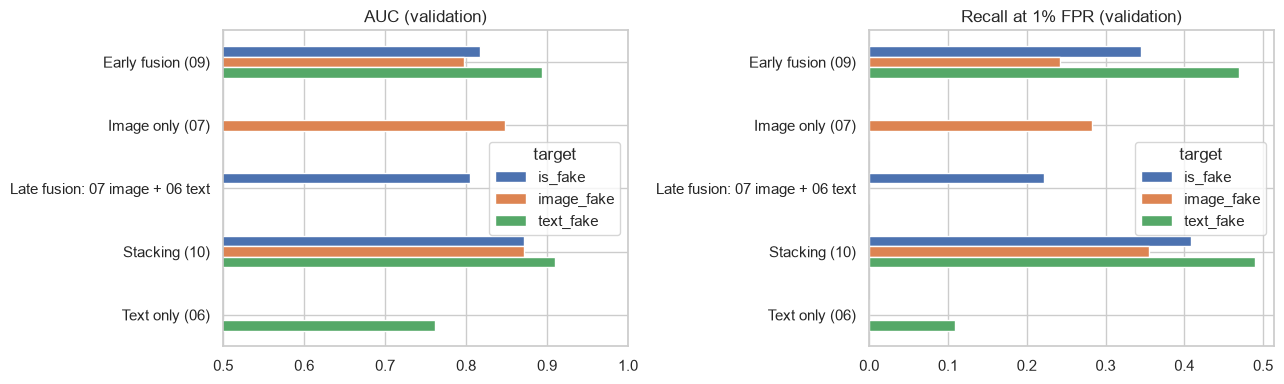

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ["AUC", "Recall at 1% FPR"]):
    results_val[metric].unstack("target")[TARGETS].plot.barh(ax=ax)
    ax.set_title(f"{metric} (validation)")
    ax.set_ylabel("")
    ax.invert_yaxis()
axes[0].set_xlim(0.5, 1.0)
plt.tight_layout()
plt.show()

## 4. What Each Model Catches

Share of each manipulation class flagged by the pair-level `is_fake` score at its 1% false-alarm threshold. For `orig` this is the false-positive rate (1% by construction).

In [6]:
by_type = pd.DataFrame({
    model: detection_rate_by_type(val, s["is_fake"], thresholds[model, "is_fake", "FPR1"])["flagged_rate"]
    for model, s in val_scores.items() if "is_fake" in s
})
by_type.loc[by_type.mean(axis=1).sort_values().index].round(3)

,Late fusion: 07 image + 06 text,Early fusion (09),Stacking (10)
fake_cls,,,
orig,0.010,0.010,0.010
text_attribute,0.139,0.063,0.047
face_swap,0.235,0.189,0.322
face_attribute,0.240,0.245,0.312
face_swap&text_attribute,0.426,0.293,0.424
text_swap,0.011,0.628,0.563
face_attribute&text_attribute,0.462,0.345,0.435
face_swap&text_swap,0.278,0.731,0.774
face_attribute&text_swap,0.258,0.783,0.787


## 5. Realistic Prevalence

Validation is ~66% fake. Per 100,000 posts at a 1% fake rate, using each model's `is_fake` 1% false-alarm threshold: how many alerts reviewers would see and how many fakes they would catch.

In [7]:
pd.concat({
    model: prevalence_table(val["is_fake"], s["is_fake"], thresholds[model, "is_fake", "FPR1"], prevalences=[0.01])
    for model, s in val_scores.items() if "is_fake" in s
}).droplevel("fake_rate").round(3)

,fakes_per_100k,alerts,fakes_caught,false_alarms,precision,recall
Late fusion: 07 image + 06 text,1000.0,1215.033,221.456,993.577,0.182,0.221
Early fusion (09),1000.0,1338.353,344.776,993.577,0.258,0.345
Stacking (10),1000.0,1402.640,409.063,993.577,0.292,0.409


**Findings (validation)**
- **Joint beats separate.** `is_fake` AUC: stacking 0.872, early fusion 0.817, late fusion of the single-mode models 0.805. At a 1% false-alarm rate they catch 41%, 34% and 22% of fake pairs.
- **The gain is swapped captions.** Late fusion catches 1% of text_swap pairs at the 1% threshold (no better than chance), early fusion 63% and stacking 56%. A swapped caption is real text about the same person, so only a model that compares it with the photo can catch it.
- **Stacking wins overall because it also keeps the image signal.** Early fusion is weaker on face edits than the image-only model (`image_fake` AUC 0.797 vs 0.848; face_swap caught 19% vs stacking's 32%). Stacking has a dedicated face-crop classifier; early fusion sees only the whole-image embedding.
- **The text model still wins on flipped words.** It catches more text_attribute pairs (14%) than either multimodal model (5–6%), since its word-level classifier targets them.

## 6. Test Evaluation (run once, at the end)

Uses the thresholds fixed on validation above. Each modelling notebook must first write its `<prefix>_test.parquet`; `10` writes it only once its own `RUN_TEST` is set.

In [8]:
if RUN_TEST:
    test, test_scores = load_scores("test")
    test_scores = {m: s for m, s in test_scores.items() if m in val_scores}
    display(results_table(test, test_scores).round(3))
    display(pd.DataFrame({
        model: detection_rate_by_type(test, s["is_fake"], thresholds[model, "is_fake", "FPR1"])["flagged_rate"]
        for model, s in test_scores.items() if "is_fake" in s
    }).round(3))
else:
    print("RUN_TEST is False: test set not evaluated.")

RUN_TEST is False: test set not evaluated.
